# Assignment: ANN Salary Regression

Use the same `Churn_Modelling.csv` dataset, but change the target to `EstimatedSalary`. Your goal is to practice how an ANN changes when the task changes from classification to regression.

## Required Changes
- Target: `EstimatedSalary`
- Remove `EstimatedSalary` from input features
- Output layer: 1 neuron with **linear** activation
- Loss: choose `mse` or `mae` and explain your choice
- Evaluation: MAE, RMSE and R2
- Save the model in `.keras` format
- Build and deploy a Streamlit salary prediction app

## Step 1 - Imports

In [1]:
# Write your imports here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

## Step 2 - Load and inspect the dataset

In [2]:
data = pd.read_csv('Churn_Modelling.csv')
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Step 3 - EDA and data quality checks

Dataset Shape: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB

Missing Values:
RowNumber          0
CustomerId         0
Surname            0
Cr

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Salary Distribution:


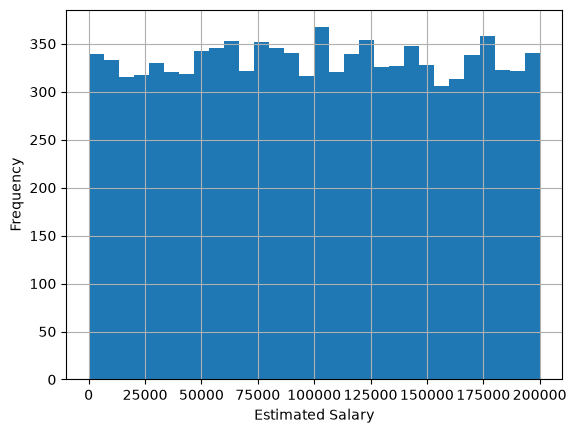

In [3]:
# shape, info, describe, missing values, duplicates, salary distribution

print("Dataset Shape:", data.shape)

data.info()

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:", data.duplicated().sum())

print("\nStatistical Summary:")
display(data.describe())

print("\nSalary Distribution:")
data["EstimatedSalary"].hist(bins=30)
plt.xlabel("Estimated Salary")
plt.ylabel("Frequency")
plt.show()

## Step 4 - Define X and y

In [4]:
# y = EstimatedSalary
# X = remaining useful features

y = data["EstimatedSalary"]

X = data.drop(columns=[
    "EstimatedSalary",
    "RowNumber",
    "CustomerId",
    "Surname"
])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", X.columns.tolist())

X shape: (10000, 10)
y shape: (10000,)
Features: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Exited']


## Step 5 - Train-test split and preprocessing

In [5]:
# Fit encoders and scaler on training data only


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

categorical_cols = X_train.select_dtypes(include=["object"]).columns
numerical_cols = X_train.select_dtypes(exclude=["object"]).columns

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
scaler = StandardScaler()

X_train_cat = encoder.fit_transform(X_train[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])

X_train_num = scaler.fit_transform(X_train[numerical_cols])
X_test_num = scaler.transform(X_test[numerical_cols])

X_train = np.hstack([X_train_num, X_train_cat])
X_test = np.hstack([X_test_num, X_test_cat])

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 13)
Testing data: (2000, 13)


C:\Users\Fast Computer\AppData\Local\Temp\ipykernel_10408\345187101.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=["object"]).columns
C:\Users\Fast Computer\AppData\Local\Temp\ipykernel_10408\345187101.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.pydata.

## Step 6 - Build a regression ANN

In [6]:
# Example structure only
# model = keras.Sequential([
#     keras.Input(shape=(X_train.shape[1],)),
#     keras.layers.Dense(64, activation='relu'),
#     keras.layers.Dense(32, activation='relu'),
#     keras.layers.Dense(1, activation='linear')
# ])

model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="linear")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

## Step 7 - Compile and train

In [7]:
# optimizer=Adam, loss='mse' or 'mae', include a suitable regression metric

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 13306116096.0000 - mae: 99967.3281 - val_loss: 13685835776.0000 - val_mae: 101978.8281
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 13182104576.0000 - mae: 99348.7109 - val_loss: 13418860544.0000 - val_mae: 100675.4922
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 12710829056.0000 - mae: 96987.0312 - val_loss: 12696907776.0000 - val_mae: 97150.0078
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 11737816064.0000 - mae: 92191.4219 - val_loss: 11432613888.0000 - val_mae: 90953.2422
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 10262466560.0000 - mae: 84856.9922 - val_loss: 9711988736.0000 - val_mae: 82414.0156
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 8461410816.0000 - mae: 75762.9609 - val_loss: 7792480256.0000 - val_mae: 72790.5469
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6637254656.0000 - mae: 66591.0625 - val_loss: 6005383680.0000 - v

## Step 8 - Evaluate

In [8]:
# Calculate MAE, RMSE and R2 on the untouched test set


y_pred = model.predict(X_test).ravel()

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE: 49850.7873321875
RMSE: 57555.19051077683
R2 Score: -0.0034370826065828197


## Step 9 - Save and reload model

In [ ]:
# model.save('salary_model.keras')

# Save the trained ANN model
# Step 9: Save and Reload Model and Preprocessing Objects


model.save("salary_model.keras")

# Save the fitted scaler
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

# Save the fitted encoder
with open("encoder.pkl", "wb") as f:
    pickle.dump(encoder, f)

# Reload the saved model
loaded_model = tf.keras.models.load_model("salary_model.keras")

# Verify saved files
import os

print("Model saved:", os.path.exists("salary_model.keras"))
print("Scaler saved:", os.path.exists("scaler.pkl"))
print("Encoder saved:", os.path.exists("encoder.pkl"))
print("Model and preprocessing objects saved successfully!")

Model saved: True
Scaler saved: True
Encoder saved: True
Model and preprocessing objects saved successfully!


## Step 10 - Streamlit deployment

In [ ]:
# Build app.py, requirements.txt and deploy on Streamlit Community Cloud




2026-10-23 22:01:36.042 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:01:36.131 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:01:36.131 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:01:36.131 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:01:36.131 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:01:36.131 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:01:36.131 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 22:01:36.131 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar